# 01 — Exploración

Cuaderno para mirar el conjunto de `data/` (compras de Black Friday) y decidir qué entrenar después. Aquí se prototipa. El entrenamiento que queda registrado vive en `src/train.py`, no en este archivo.

El objetivo es predecir `Purchase`, el valor de la compra, así que es un problema de **regresión**.

## Qué revisar

- Qué archivo hay en `DATA_PATH` y cuántas filas y columnas tiene.
- Qué columna es el objetivo y cuáles son las features.
- Valores ausentes, rangos y datos atípicos.
- Una partición de prueba, con la misma semilla que `src/config.py` (`RANDOM_SEED`), para no comparar resultados distintos por azar.
- Un modelo de prueba, solo para ver si el problema está bien planteado. Esas pruebas no se registran como el modelo `challenger`.

In [20]:
import pandas as pd # manejo de datos
import matplotlib.pyplot as plt # graficos
from sklearn.model_selection import train_test_split # division de datos en entrenamiento y prueba
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler # preprocesamiento de datos
# importar modelos de regresion
from sklearn.linear_model import LinearRegression # regresion lineal
from sklearn.tree import DecisionTreeRegressor # arboles de decision
from sklearn.ensemble import RandomForestRegressor # random forest
from sklearn.ensemble import HistGradientBoostingRegressor # gradient boosting
# importar metricas
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error # Metricas para regresion
import joblib
import json

In [21]:
ruta_datos = "../data/train.csv"

df_compras = pd.read_csv(ruta_datos)

df_compras.head(3)

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422


In [22]:
df_compras.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     550068 non-null  int64  
 1   Product_ID                  550068 non-null  object 
 2   Gender                      550068 non-null  object 
 3   Age                         550068 non-null  object 
 4   Occupation                  550068 non-null  int64  
 5   City_Category               550068 non-null  object 
 6   Stay_In_Current_City_Years  550068 non-null  object 
 7   Marital_Status              550068 non-null  int64  
 8   Product_Category_1          550068 non-null  int64  
 9   Product_Category_2          376430 non-null  float64
 10  Product_Category_3          166821 non-null  float64
 11  Purchase                    550068 non-null  int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 50.4+ MB


In [23]:
# eliminar duplicados
df_compras = df_compras.drop_duplicates()
df_compras.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     550068 non-null  int64  
 1   Product_ID                  550068 non-null  object 
 2   Gender                      550068 non-null  object 
 3   Age                         550068 non-null  object 
 4   Occupation                  550068 non-null  int64  
 5   City_Category               550068 non-null  object 
 6   Stay_In_Current_City_Years  550068 non-null  object 
 7   Marital_Status              550068 non-null  int64  
 8   Product_Category_1          550068 non-null  int64  
 9   Product_Category_2          376430 non-null  float64
 10  Product_Category_3          166821 non-null  float64
 11  Purchase                    550068 non-null  int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 50.4+ MB


In [24]:
# revisar datos nulos
df_compras.isnull().sum()

User_ID                            0
Product_ID                         0
Gender                             0
Age                                0
Occupation                         0
City_Category                      0
Stay_In_Current_City_Years         0
Marital_Status                     0
Product_Category_1                 0
Product_Category_2            173638
Product_Category_3            383247
Purchase                           0
dtype: int64

`Product_Category_2` y `Product_Category_3` tienen muchos nulos porque varios productos solo pertenecen a una categoría. Si se eliminaran las filas con nulos se perdería casi todo el conjunto, así que un nulo se interpreta como *sin categoría* y se rellena con 0.

In [25]:
# rellenar con 0 las categorias de producto vacias (sin categoria)
df_compras[['Product_Category_2', 'Product_Category_3']] = df_compras[['Product_Category_2', 'Product_Category_3']].fillna(0)
df_compras.isnull().sum().sum()

np.int64(0)

In [26]:
# Eliminar las columnas de identificador: User_ID y Product_ID tienen miles de valores
# distintos y codificarlas como numeros no aporta informacion al modelo
df_compras = df_compras.drop(columns=['User_ID', 'Product_ID'])
df_compras.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 10 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Gender                      550068 non-null  object 
 1   Age                         550068 non-null  object 
 2   Occupation                  550068 non-null  int64  
 3   City_Category               550068 non-null  object 
 4   Stay_In_Current_City_Years  550068 non-null  object 
 5   Marital_Status              550068 non-null  int64  
 6   Product_Category_1          550068 non-null  int64  
 7   Product_Category_2          550068 non-null  float64
 8   Product_Category_3          550068 non-null  float64
 9   Purchase                    550068 non-null  int64  
dtypes: float64(2), int64(4), object(4)
memory usage: 42.0+ MB


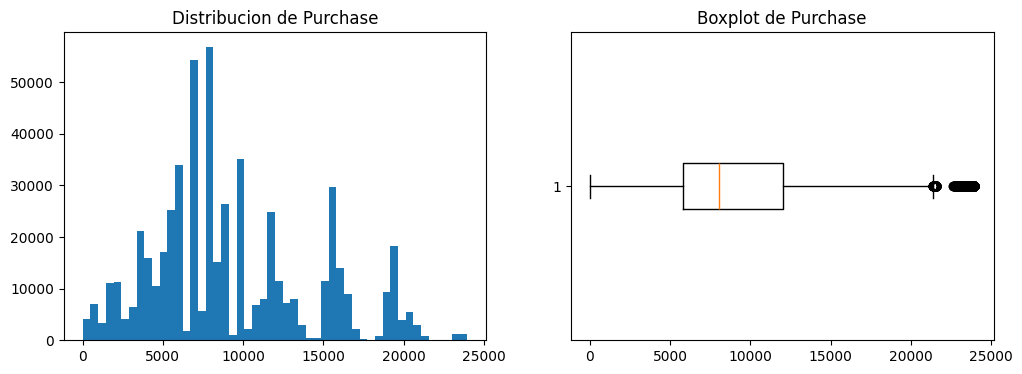

count    550068.000000
mean       9263.968713
std        5023.065394
min          12.000000
25%        5823.000000
50%        8047.000000
75%       12054.000000
max       23961.000000
Name: Purchase, dtype: float64

In [27]:
# Analizar la variable objetivo Purchase y buscar datos atipicos
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].hist(df_compras['Purchase'], bins=50)
ejes[0].set_title('Distribucion de Purchase')
ejes[1].boxplot(df_compras['Purchase'], vert=False)
ejes[1].set_title('Boxplot de Purchase')
plt.show()

df_compras['Purchase'].describe()

`Purchase` no tiene valores absurdos, así que no se elimina ninguna fila por atípicos.

In [28]:
mapeos_encoer = {} # Definir un diccionario vacio
columna_texto = df_compras.select_dtypes(include=['object', 'string']).columns

for columna in columna_texto:
    le = LabelEncoder()
    df_compras[columna] = le.fit_transform(df_compras[columna])
    print(f'columna {columna} transformada: {le.classes_}')

    mapeos_encoer[columna] = le.classes_.tolist()

ruta_mapeo_encoder = "mapeo_encoder_black_friday.json"

with open(ruta_mapeo_encoder, 'w') as archivo:
    json.dump(mapeos_encoer, archivo, indent=4)

df_compras.head(3)

columna Gender transformada: ['F' 'M']
columna Age transformada: ['0-17' '18-25' '26-35' '36-45' '46-50' '51-55' '55+']
columna City_Category transformada: ['A' 'B' 'C']
columna Stay_In_Current_City_Years transformada: ['0' '1' '2' '3' '4+']


,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,0,0,10,0,2,0,3,0.0,0.0,8370
1,0,0,10,0,2,0,1,6.0,14.0,15200
2,0,0,10,0,2,0,12,0.0,0.0,1422


In [29]:
# definir el StandScaler()
scaler = StandardScaler()
# Entrenar el StandScaler() con las columnas de interes.
columnas_numericas = df_compras.drop(columns=columna_texto).columns
# en este caso se deben omitir las columnas que se selecionaron en la variable
# columnas_texto ya que son las que labelencoder proceso.
# asegurar que la columna variable objetivo no se preprocese con standscaler.
columnas_numericas = columnas_numericas.drop('Purchase')
scaler.fit(df_compras[columnas_numericas])

# Transfromar los datos con el scaler entrenado
df_compras_escalado = df_compras.copy()
df_compras_escalado[columnas_numericas] = scaler.transform(df_compras[columnas_numericas])
df_compras_escalado.info()

# Si al final mi mejor modelo es con datos scalados es necesario guardar ls informacion del escalador

ruta_escalador = "scaler_black_friday.pkl"

joblib.dump(scaler, ruta_escalador)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 10 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Gender                      550068 non-null  int64  
 1   Age                         550068 non-null  int64  
 2   Occupation                  550068 non-null  float64
 3   City_Category               550068 non-null  int64  
 4   Stay_In_Current_City_Years  550068 non-null  int64  
 5   Marital_Status              550068 non-null  float64
 6   Product_Category_1          550068 non-null  float64
 7   Product_Category_2          550068 non-null  float64
 8   Product_Category_3          550068 non-null  float64
 9   Purchase                    550068 non-null  int64  
dtypes: float64(5), int64(5)
memory usage: 42.0 MB


['scaler_black_friday.pkl']

In [30]:
# Definir matriz "X" y objetivo "y"
X_scale = df_compras_escalado.drop('Purchase', axis=1)
y_scale = df_compras_escalado['Purchase']


In [31]:
# Dividir datos en entrenamiento y prueba

X_train_scale, X_test_scale, y_train_scale, y_test_scale = train_test_split(X_scale, y_scale, test_size=0.3, random_state=42)

print("Tamaño X_train_scale: ",X_train_scale.shape)
print("Tamaño y_train_scale: ",y_train_scale.shape)

print("Tamaño X_test_scale: ",X_test_scale.shape)
print("Tamaño y_test_scale",y_test_scale.shape)

Tamaño X_train_scale:  (385047, 9)
Tamaño y_train_scale:  (385047,)
Tamaño X_test_scale:  (165021, 9)
Tamaño y_test_scale (165021,)


Se prueban cuatro estrategias de regresión. La máquina de soporte vectorial (`SVR`) se deja por fuera porque con más de 380 mil filas de entrenamiento tarda demasiado; en su lugar se usa `HistGradientBoostingRegressor`.

In [32]:
# Definir estrategia o modelos y entrenarlos

# Modelo de regresion lineal
modelo_lr_s = LinearRegression()
modelo_lr_s.fit(X_train_scale, y_train_scale)

# Modelo de arbol
modelo_dt_s = DecisionTreeRegressor(max_depth=10, random_state=42)
modelo_dt_s.fit(X_train_scale, y_train_scale)

# Modelo de bosques aleatorios
modelo_rf_s = RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42)
modelo_rf_s.fit(X_train_scale, y_train_scale)

# Modelo de gradient boosting
modelo_hgb_s = HistGradientBoostingRegressor(random_state=42)
modelo_hgb_s.fit(X_train_scale, y_train_scale)

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [33]:
# Hacer predicciones con cada modelo y los datos de prueba

y_pred_lr_s = modelo_lr_s.predict(X_test_scale)
y_pred_dt_s = modelo_dt_s.predict(X_test_scale)
y_pred_rf_s = modelo_rf_s.predict(X_test_scale)
y_pred_hgb_s = modelo_hgb_s.predict(X_test_scale)

In [34]:
# Calcular las metricas para determinar que estrategia es mejor y definir
# si se resuelve o no el problema

r2_lr_s = r2_score(y_test_scale, y_pred_lr_s)
r2_dt_s = r2_score(y_test_scale, y_pred_dt_s)
r2_rf_s = r2_score(y_test_scale, y_pred_rf_s)
r2_hgb_s = r2_score(y_test_scale, y_pred_hgb_s)

mae_lr_s = mean_absolute_error(y_test_scale, y_pred_lr_s)
mae_dt_s = mean_absolute_error(y_test_scale, y_pred_dt_s)
mae_rf_s = mean_absolute_error(y_test_scale, y_pred_rf_s)
mae_hgb_s = mean_absolute_error(y_test_scale, y_pred_hgb_s)

print("Metrica R2 de modelos (mas cercano a 1 es mejor)")
print("Regresion lineal scale: ", r2_lr_s)
print("Arbol de decision scale: ", r2_dt_s)
print("Random forest scale: ", r2_rf_s)
print("Gradient boosting scale: ", r2_hgb_s)

print()
print("Metrica MAE de modelos (error promedio en la compra, menor es mejor)")
print("Regresion lineal scale: ", mae_lr_s)
print("Arbol de decision scale: ", mae_dt_s)
print("Random forest scale: ", mae_rf_s)
print("Gradient boosting scale: ", mae_hgb_s)

Metrica R2 de modelos (mas cercano a 1 es mejor)
Regresion lineal scale:  0.15022258480005324
Arbol de decision scale:  0.6498993528348342
Random forest scale:  0.6580808201010324
Gradient boosting scale:  0.6615644723129276

Metrica MAE de modelos (error promedio en la compra, menor es mejor)
Regresion lineal scale:  3529.275460797314
Arbol de decision scale:  2225.443577682475
Random forest scale:  2201.1725095531588
Gradient boosting scale:  2195.010547883838


## Conclusión

- **Objetivo:** `Purchase`. **Features:** 9 columnas (`Gender`, `Age`, `Occupation`, `City_Category`, `Stay_In_Current_City_Years`, `Marital_Status` y las tres `Product_Category`), codificadas y escaladas.
- **Métrica para elegir el mejor run:** R2 (y MAE como apoyo).
- **Resultado:** la regresión lineal rinde poco, porque la relación entre la categoría del producto y la compra no es lineal. Los modelos basados en árboles mejoran bastante, y `hist_gradient_boosting` y `random_forest` quedan prácticamente empatados.
- **Datos que no deben subirse a Git:** `data/train.csv` (25 MB).